In [1]:
import os

In [2]:
import deepxde as dde
import numpy as np
import matplotlib.pyplot as plt

Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.


1. Define the Physics (Navier-Stokes Equations of 2D Steady Flow)

In [17]:
def navier_stokes_2d(x,y):
    u = y[:, 0:1]
    v = y[:, 1:2]
    p = y[:, 2:3]
    nu = 0.01 # Kinematic Viscosity
    
    u_x = dde.grad.jacobian(y, x, i=0, j=0)
    u_y = dde.grad.jacobian(y, x, i=0, j=1)
    v_x = dde.grad.jacobian(y, x, i=1, j=0)
    v_y = dde.grad.jacobian(y, x, i=1, j=1)
    p_x = dde.grad.jacobian(y, x, i=2, j=0)
    p_y = dde.grad.jacobian(y, x, i=2, j=1)
    
    u_xx = dde.grad.hessian(y, x, component=0, i=0, j=0)
    u_yy = dde.grad.hessian(y, x, component=0, i=0, j=1)
    v_xx = dde.grad.hessian(y, x, component=1, i=0, j=0)
    v_yy = dde.grad.hessian(y, x, component=1, i=0, j=1)
    
    #Governing System Equations
    continuity = u_x + v_y
    x_momentum = u * u_x + v * u_y + p_x - nu * (u_xx + u_yy)
    y_momentum = u * v_x + v * v_y + p_y - nu * (v_xx + v_yy)
    
    return [continuity, x_momentum, y_momentum]

2. Define Domain Dimensions and Central Cylinder obstacle

In [18]:
x_min, x_max = 0.0, 2.0
y_min, y_max = 0.0, 1.0
cx, cy, radius = 1.0, 0.5, 0.15 # Cylinder placement parameters

channel = dde.geometry.Rectangle([x_min, y_min], [x_max, y_max])
cylinder = dde.geometry.Disk([cx, cy], radius)

#Geometry subtraction leaves a Literal Physical hole in the network mesh
geom = channel - cylinder


In [4]:
# For a Triangle 
# vertices = ([0.0, 0.0], [1.0, 0.0], [0.0, 1.0])
# triangle = dde.geometry.Polygon(vertices)
# geom = channel - triangle

3. Hard-Code No-slip Boundary Constraints onto the Cylinder Wall

In [19]:
def on_cylinder(x, on_boundary):
    return on_boundary and np.isclose(np.linalg.norm(x - [cx, cy]), radius)

bc_cylinder_u = dde.icbc.DirichletBC(geom, lambda x: 0, on_cylinder, component=0)
bc_cylinder_v = dde.icbc.DirichletBC(geom, lambda x: 0, on_cylinder, component=1)

4. Synthesize Mock Downstream Experimental PIV Measurement Targers

In [20]:
np.random.seed(42)
num_data_points = 60
sensor_x_min, sensor_x_max = 1.3, 1.8

# Generate scattered coordinate point positions downstream of the boundary hole
observed_x = np.random.uniform([sensor_x_min, 0.1], [sensor_x_max, 0.9], (num_data_points, 2))
observed_u = np.ones((num_data_points, 1)) * 0.5
observed_v = np.zeros((num_data_points, 1))

observe_u = dde.icbc.PointSetBC(observed_x, observed_u, component=0)
observe_v = dde.icbc.PointSetBC(observed_x, observed_v, component=1)


5. Compile Global Training Container

In [21]:
data = dde.data.PDE(
    geom, 
    navier_stokes_2d,
    [bc_cylinder_u, bc_cylinder_v,observe_u, observe_v],
    num_domain=2500,
    num_boundary=300,
    anchors=observed_x
)

loss_weights = [20.0, 20.0, 20.0, 1.0, 1.0, 1.0, 1.0]

6. Build the fully Connected Neural Network (FNN) Graph


In [22]:
layer_size = [2, 64, 64, 64, 3] 
net = dde.nn.FNN(layer_size, "tanh", "Glorot uniform")

model = dde.Model(data, net)
model.compile(optimizer="adam", lr=0.001, loss_weights=loss_weights)

Compiling model...
'compile' took 0.000330 s



In [23]:
class SoftmaxAdaptiveWeights(dde.callbacks.Callback):
    def __init__(self, model, every_n_epochs=100, alpha_0=1.0, gamma=0.999):
        super().__init__()
        self.model = model
        self.every_n_epochs = every_n_epochs
        self.alpha = alpha_0
        self.gamma = gamma
        self.epoch = 0

    def on_epoch_end(self):
        self.epoch += 1
        if self.epoch % self.every_n_epochs != 0:
            return
        if len(self.model.losshistory.loss_train) == 0:
            return
        current_losses = self.model.losshistory.loss_train[-1]
        exp_terms = np.exp(self.alpha * np.array(current_losses))
        new_weights = exp_terms / (np.sum(exp_terms) + 1e-8)
        self.alpha *= self.gamma
        self.model.loss_weights = new_weights.tolist()
        # print(f"Epoch {self.epoch}: Adaptive weights updated to {new_weights.tolist()}, alpha decayed to {self.alpha:.4f}")

adaptive_callback = SoftmaxAdaptiveWeights(model, every_n_epochs=20)

7. Execute Training Convergence Optimization

In [29]:
print("Executing PINN solver Optimization loop...")
model.train(iterations=5000, display_every=500, callbacks=[adaptive_callback])

Executing PINN solver Optimization loop...
Training model...

Step      Train loss                                                                Test loss                                                                 Test metric
5000      [2.86e-04, 1.38e-04, 1.82e-05, 1.52e-03, 4.68e-04, 1.83e-03, 9.59e-04]    [2.86e-04, 1.38e-04, 1.82e-05, 1.52e-03, 4.68e-04, 1.83e-03, 9.59e-04]    []  


5500      [2.91e-04, 1.42e-04, 1.67e-05, 1.53e-03, 4.90e-04, 1.78e-03, 9.20e-04]    [2.91e-04, 1.42e-04, 1.67e-05, 1.53e-03, 4.90e-04, 1.78e-03, 9.20e-04]    []  
6000      [2.98e-04, 1.40e-04, 1.64e-05, 1.52e-03, 4.96e-04, 1.74e-03, 8.93e-04]    [2.98e-04, 1.40e-04, 1.64e-05, 1.52e-03, 4.96e-04, 1.74e-03, 8.93e-04]    []  
6500      [3.08e-04, 1.48e-04, 1.28e-05, 1.50e-03, 4.83e-04, 1.68e-03, 8.60e-04]    [3.08e-04, 1.48e-04, 1.28e-05, 1.50e-03, 4.83e-04, 1.68e-03, 8.60e-04]    []  
7000      [3.45e-04, 1.68e-04, 2.83e-05, 1.35e-03, 3.96e-04, 1.56e-03, 7.92e-04]    [3.45e-04, 1.68e-04, 2.83e-05, 1.35e-03, 3.96e-04, 1.56e-03, 7.92e-04]    []  
7500      [3.62e-04, 1.81e-04, 6.93e-05, 1.15e-03, 3.58e-04, 1.35e-03, 8.04e-04]    [3.62e-04, 1.81e-04, 6.93e-05, 1.15e-03, 3.58e-04, 1.35e-03, 8.04e-04]    []  
8000      [3.60e-04, 1.54e-04, 9.29e-05, 9.55e-04, 3.20e-04, 1.16e-03, 8.62e-04]    [3.60e-04, 1.54e-04, 9.29e-05, 9.55e-04, 3.20e-04, 1.16e-03, 8.62e-04]    []  
8500      [3.47e-04, 1

(<deepxde.model.LossHistory at 0x7af71a3c9950>,
 <deepxde.model.TrainState at 0x7af71a3c9810>)

8. Post-Processing: Compute Mesh Grid and Predictions

In [30]:
nx, ny = 200, 100
x_flat = np.linspace(x_min, x_max, nx)
y_flat = np.linspace(y_min, y_max, ny)
X, Y = np.meshgrid(x_flat, y_flat)
test_domain = np.vstack((X.flatten(), Y.flatten())).T

predictions = model.predict(test_domain)
u_pred = predictions[:, 0].reshape(ny, nx)
v_pred = predictions[:, 1].reshape(ny, nx)
p_pred = predictions[:, 2].reshape(ny, nx)

9. Dynamic Mesh Masking Configuration

In [31]:
distance_from_center = np.sqrt((X - cx)**2 + (Y - cy)**2)
cylinder_mask = distance_from_center <= radius

u_pred = np.ma.masked_where(cylinder_mask, u_pred)
v_pred = np.ma.masked_where(cylinder_mask, v_pred)
p_pred = np.ma.masked_where(cylinder_mask, p_pred)

10. Execute figure Matplotlib PIpeline

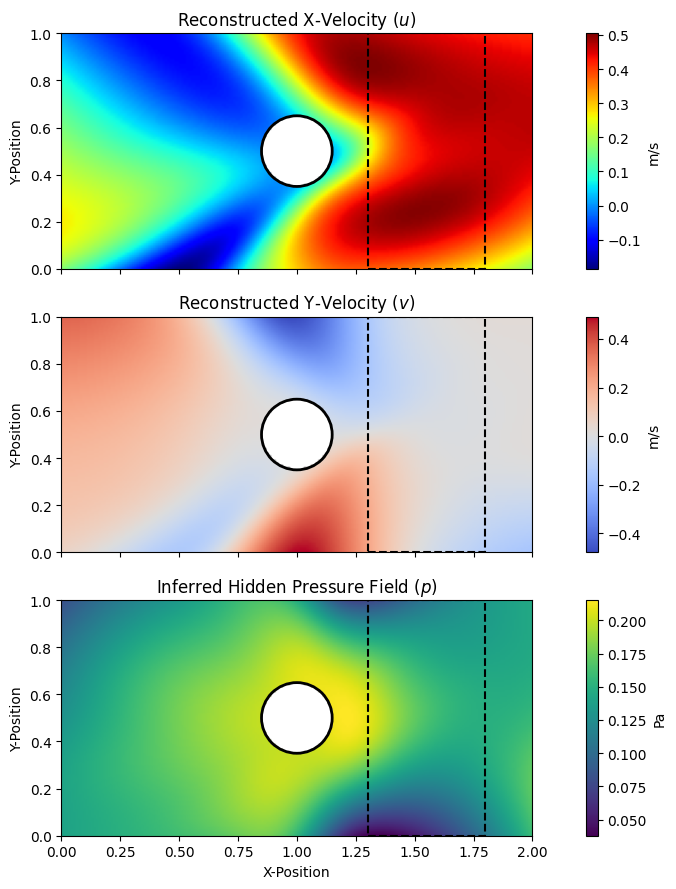

In [32]:
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
extent = [x_min, x_max, y_min, y_max]

# Plot Panel 1: X-Velocity (u)
im0 = axes[0].imshow(u_pred, extent=extent, origin='lower', cmap='jet', aspect='equal')
axes[0].set_title('Reconstructed X-Velocity ($u$)')
fig.colorbar(im0, ax=axes[0], label='m/s')

# Plot Panel 2: Y-Velocity (v)
im1 = axes[1].imshow(v_pred, extent=extent, origin='lower', cmap='coolwarm', aspect='equal')
axes[1].set_title('Reconstructed Y-Velocity ($v$)')
fig.colorbar(im1, ax=axes[1], label='m/s')

# Plot Panel 3: Inferred Hidden Fluid Pressure (p)
im2 = axes[2].imshow(p_pred, extent=extent, origin='lower', cmap='viridis', aspect='equal')
axes[2].set_title('Inferred Hidden Pressure Field ($p$)')
fig.colorbar(im2, ax=axes[2], label='Pa')

# Annotate Physical Boundaries and Sensor Windows across all panels
for ax in axes:
    # Overlay the structural hard outline boundary around the cylinder disk
    circle_outline = plt.Circle((cx, cy), radius, color='black', fill=False, linewidth=2)
    ax.add_patch(circle_outline)
    
    # Overlay the boundaries showing where mock PIV readings were extracted
    sensor_box = plt.Rectangle((sensor_x_min, y_min), (sensor_x_max - sensor_x_min), y_max, 
                               linewidth=1.5, edgecolor='black', facecolor='none', linestyle='--')
    ax.add_patch(sensor_box)
    ax.set_ylabel('Y-Position')

axes[2].set_xlabel('X-Position')
plt.tight_layout()

# Save final graphic locally
plt.savefig('pinn_cylinder_flow_field.png', dpi=300)
plt.show()